## Sales Prediction and Business Insights

#### Objective
The purpose of this notebook is to identify the vehicle characteristics that influence sales performance and build a regression model to predict vehicle sales.
#### Workflow

- Feature Engineering
- Feature Selection
- Regression Modeling
- Model Evaluation
- Business Insights
- Final Recommendations

In [6]:
# Import necessary libraries 
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

# Load cleaned dataset
df = pd.read_csv("../data/processed/car_sales_clean.csv")

# Restore important data types
df["Latest_Launch"] = pd.to_datetime(df["Latest_Launch"])

cat_cols = ["Manufacturer", "Model", "Vehicle_type"]
df[cat_cols] = df[cat_cols].astype("category")

df.head()

,Manufacturer,Model,Sales_in_thousands,__year_resale_value,Vehicle_type,Price_in_thousands,Engine_size,Horsepower,Wheelbase,Width,Length,Curb_weight,Fuel_capacity,Fuel_efficiency,Latest_Launch,Power_perf_factor
0,Acura,Integra,16.919,16.360,Passenger,21.500,1.8,140.0,101.2,67.3,172.4,2.639,13.2,28.0,2012-02-02,58.280150
1,Acura,TL,39.384,19.875,Passenger,28.400,3.2,225.0,108.1,70.3,192.9,3.517,17.2,25.0,2011-06-03,91.370778
2,Acura,CL,14.114,18.225,Passenger,22.799,3.2,225.0,106.9,70.6,192.0,3.470,17.2,26.0,2012-01-04,72.030917
3,Acura,RL,8.588,29.725,Passenger,42.000,3.5,210.0,114.6,71.4,196.6,3.850,18.0,22.0,2011-03-10,91.389779
4,Audi,A4,20.397,22.255,Passenger,23.990,1.8,150.0,102.6,68.2,178.0,2.998,16.4,27.0,2011-10-08,62.777639


#### 1. Feature Engineering

Feature engineering involves creating new features from existing variables to improve analysis and modeling.

In this project, the launch year is extracted from the vehicle launch date to investigate whether newer vehicle models tend to achieve higher sales.

In [7]:
# Extract launch year
df["Launch_Year"] = df["Latest_Launch"].dt.year

# Verify result
df[["Latest_Launch", "Launch_Year"]].head()

,Latest_Launch,Launch_Year
0,2012-02-02,2012
1,2011-06-03,2011
2,2012-01-04,2012
3,2011-03-10,2011
4,2011-10-08,2011


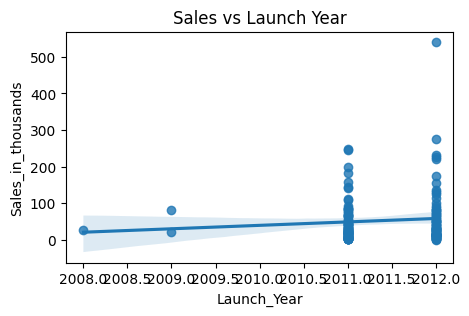

In [12]:
# Analyze Launch Year
plt.figure(figsize=(5, 3))
sns.regplot(data=df, x="Launch_Year", y="Sales_in_thousands")

plt.title("Sales vs Launch Year")
plt.show()

- The plot shows a very slight positive trend, but the relationship is quite weak. Newer vehicle models tend to achieve slightly higher sales volumes, as indicated by the weak upward trend in the regression line.
- The wide spread of data points suggests that launch year alone has limited influence on sales performance, and other vehicle characteristics play a more important role.


### 2. Feature Selection  
Before building the regression model, it is important to identify the target variable and predictor variables.

- Target Variable : `Sales_in_thousands`
- Selected Features : Based on the EDA findings, the following features were selected for modeling:

Numerical Features
- `Price_in_thousands`
- `Wheelbase`
- `Launch_Year`

Categorical Feature
- `Vehicle_type`

In [ ]:
# Select features for modeling
model_df = df[
    [
        "Sales_in_thousands",
        "Price_in_thousands",
        "Wheelbase",
        "Launch_Year",
        "Vehicle_type"
    ]
].copy()
# Create a copy to avoid modifying the original dataframe
model_df.head()

,Sales_in_thousands,Price_in_thousands,Wheelbase,Launch_Year,Vehicle_type
0,16.919,21.500,101.2,2012,Passenger
1,39.384,28.400,108.1,2011,Passenger
2,14.114,22.799,106.9,2012,Passenger
3,8.588,42.000,114.6,2011,Passenger
4,20.397,23.990,102.6,2011,Passenger


## Multiple Linear Regression

To understand the relationship between vehicle characteristics and sales performance, a Multiple Linear Regression model is built using the selected numerical features.

### Target Variable

- `Sales_in_thousands`

### Predictor Variables

- `Price_in_thousands`
- `Wheelbase`
- `Launch_Year`

These variables were selected based on the findings from the exploratory data analysis.

In [24]:
# Predictor variables
X = model_df[
    [
        "Price_in_thousands",
        "Wheelbase",
        "Launch_Year"
    ]
]

# Target variable
y = model_df["Sales_in_thousands"]

# Add intercept
X = sm.add_constant(X)

# Fit regression model
model = sm.OLS(y, X).fit()

# Model summary
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:     Sales_in_thousands   R-squared:                       0.250
Model:                            OLS   Adj. R-squared:                  0.236
Method:                 Least Squares   F-statistic:                     17.02
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           1.37e-09
Time:                        14:35:53   Log-Likelihood:                -862.19
No. Observations:                 157   AIC:                             1732.
Df Residuals:                     153   BIC:                             1745.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const              -1.225e+04   1.52

#### Feature Selection Conclusion

Although Launch_Year was engineered from the Latest_Launch feature and included in the initial regression model, it was found to be statistically insignificant (p-value > 0.05).

Since removing Launch_Year had a negligible impact on model performance, it was excluded from the final model to improve simplicity and interpretability.

#### Regression Model Observations

- The model explains approximately **25% of the variation in vehicle sales** (R² = 0.25), indicating that the selected features have a moderate ability to predict sales performance.

- `Price_in_thousands` and `Wheelbase` are statistically significant predictors of sales (**p-value < 0.05**), while `Launch_Year` is not statistically significant.

- `Price_in_thousands` has a negative coefficient (-1.65), suggesting that higher-priced vehicles tend to achieve lower sales volumes.

- `Wheelbase` has a positive coefficient (3.51), indicating that vehicles with a larger wheelbase tend to achieve higher sales volumes.

- The overall regression model is statistically significant (**Prob(F-statistic) < 0.05**), suggesting that the predictors collectively contribute to explaining vehicle sales.

### Main Business Insight: 
Among the selected features, Price_in_thousands and Wheelbase have the strongest influence on vehicle sales. Lower-priced vehicles tend to sell more, while larger vehicles tend to achieve higher sales volumes.